# Q7 — Cursos de Ciência da Computação com mais alunos trabalhando têm alunos que estudam menos fora da sala de aula?

**Variáveis:** QE_I10, QE_I23 (agregadas por CO_CURSO) · **Arquivos:** arq16, arq29 (+ arq1 para CO_GRUPO)

**Hipótese:** Entre os cursos de Ciência da Computação do Brasil, quanto maior o percentual de concluintes que trabalham mais de 20 horas semanais, maior o percentual que estuda menos de 8 horas semanais fora da sala de aula.

> A análise é feita no nível do curso porque QE_I10 e QE_I23 estão em arquivos separados, sem identificador de aluno: só é possível comparar percentuais agregados por CO_CURSO, nunca o mesmo estudante nas duas perguntas.

In [1]:
# Centraliza bibliotecas e constantes usadas em toda a análise da Q7.
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# códigos derivados em analyze.ipynb
CO_IES_UNIFOR = 555
CO_CURSO_UNIFOR_CC = 11730

DATA_DIR = "../data/2021"
N_MINIMO_POR_CURSO = 5
N_PERMUTACOES = 10_000
rng = np.random.default_rng(42)

## Dados

Categorias conferidas no dicionário de variáveis do INEP (`data/2021_leia-me`). Definições operacionais:

- **Trabalha mais de 20h** = `QE_I10 ∈ {D, E}` (21 a 39 horas ou 40 horas ou mais; o item exclui estágio e bolsas).
- **Estuda menos de 8h** = `QE_I23 ∈ {A, B, C}` (nenhuma, 1 a 3 ou 4 a 7 horas semanais fora da aula).
- **Trabalha regularmente** (só para a checagem de robustez) = `QE_I10 ∈ {C, D, E}`.
- Respostas em branco ou fora de A–E são excluídas e contadas na linha de base. O questionário não é filtrado por presença na prova, pois a presença está no arq3 e exigiria cruzar arquivos no nível do aluno.

In [2]:
# Lê o cadastro de cursos (arq1) e os dois itens do questionário em leituras independentes (arq16 e arq29).
cursos = pd.read_csv(
    f"{DATA_DIR}/microdados2021_arq1.txt",
    sep=";",
    encoding="ISO-8859-1",
    usecols=["CO_CURSO", "CO_IES", "CO_GRUPO"],
).drop_duplicates(subset="CO_CURSO")
trabalho = pd.read_csv(
    f"{DATA_DIR}/microdados2021_arq16.txt",
    sep=";",
    encoding="ISO-8859-1",
    usecols=["CO_CURSO", "QE_I10"],
)
estudo = pd.read_csv(
    f"{DATA_DIR}/microdados2021_arq29.txt",
    sep=";",
    encoding="ISO-8859-1",
    usecols=["CO_CURSO", "QE_I23"],
)

In [3]:
# Restringe cada item aos cursos de CC e marca as definições operacionais sobre as respostas válidas.
curso_unifor = cursos[cursos["CO_CURSO"] == CO_CURSO_UNIFOR_CC]
assert (len(curso_unifor) == 1) and (curso_unifor["CO_IES"].iloc[0] == CO_IES_UNIFOR)
CO_GRUPO_CC = curso_unifor["CO_GRUPO"].iloc[0]
cursos_cc = cursos.loc[cursos["CO_GRUPO"] == CO_GRUPO_CC, "CO_CURSO"]
print(f"CO_GRUPO de Ciência da Computação: {CO_GRUPO_CC} ({len(cursos_cc)} cursos)")

rotulos_qe_i10 = {
    "A": "Não estou trabalhando",
    "B": "Trabalho eventualmente",
    "C": "Trabalho até 20 horas semanais",
    "D": "Trabalho de 21 a 39 horas semanais",
    "E": "Trabalho 40 horas semanais ou mais",
}
rotulos_qe_i23 = {
    "A": "Nenhuma, apenas assisto às aulas",
    "B": "De uma a três",
    "C": "De quatro a sete",
    "D": "De oito a doze",
    "E": "Mais de doze",
}

trabalho_cc = trabalho[trabalho["CO_CURSO"].isin(cursos_cc)]
estudo_cc = estudo[estudo["CO_CURSO"].isin(cursos_cc)]

m_valido_qe_i10 = trabalho_cc["QE_I10"].isin(rotulos_qe_i10)
m_valido_qe_i23 = estudo_cc["QE_I23"].isin(rotulos_qe_i23)

trabalho_validos = trabalho_cc[m_valido_qe_i10].copy()
trabalho_validos["trab_20h"] = trabalho_validos["QE_I10"].isin(["D", "E"])
trabalho_validos["trab_regular"] = trabalho_validos["QE_I10"].isin(["C", "D", "E"])

estudo_validos = estudo_cc[m_valido_qe_i23].copy()
estudo_validos["estuda_menos_8h"] = estudo_validos["QE_I23"].isin(["A", "B", "C"])

CO_GRUPO de Ciência da Computação: 4004 (329 cursos)


In [4]:
# Informa, para cada item, quantas respostas de cursos de CC entram e quantas ficam de fora.
bases = {
    "QE_I10 (arq16)": m_valido_qe_i10,
    "QE_I23 (arq29)": m_valido_qe_i23,
}
for item, m_valido in bases.items():
    n_validos = m_valido.sum()
    n_excluidos = (~m_valido).sum()
    motivo = f"{item}, cursos de CC: respostas em branco ou fora de A–E"
    print(f"Base: {n_validos} registros válidos; {n_excluidos} excluídos ({motivo}).")

Base: 11118 registros válidos; 1615 excluídos (QE_I10 (arq16), cursos de CC: respostas em branco ou fora de A–E).
Base: 11116 registros válidos; 1617 excluídos (QE_I23 (arq29), cursos de CC: respostas em branco ou fora de A–E).


## Resultados

In [5]:
# Agrega cada item por curso e junta só as tabelas agregadas; esta é a fonte dos números seguintes.
por_curso_qe_i10 = trabalho_validos.groupby("CO_CURSO").agg(
    n_qe_i10=("trab_20h", "size"),
    pct_trab_20h=("trab_20h", "mean"),
    pct_trab_regular=("trab_regular", "mean"),
)
por_curso_qe_i23 = estudo_validos.groupby("CO_CURSO").agg(
    n_qe_i23=("estuda_menos_8h", "size"),
    pct_estuda_menos_8h=("estuda_menos_8h", "mean"),
)
colunas_pct = ["pct_trab_20h", "pct_trab_regular", "pct_estuda_menos_8h"]
tabela_todos_cursos = por_curso_qe_i10.merge(
    por_curso_qe_i23, on="CO_CURSO", how="inner", validate="one_to_one"
)
tabela_todos_cursos[colunas_pct] = tabela_todos_cursos[colunas_pct] * 100

m_n_suficiente = (tabela_todos_cursos["n_qe_i10"] >= N_MINIMO_POR_CURSO) & (
    tabela_todos_cursos["n_qe_i23"] >= N_MINIMO_POR_CURSO
)
tabela_cursos = tabela_todos_cursos[m_n_suficiente].copy()
n_cursos = len(tabela_cursos)
print(
    f"Cursos de CC: {len(cursos_cc)}; analisados (n ≥ {N_MINIMO_POR_CURSO} nos dois itens): {n_cursos}; "
    f"descartados: {len(cursos_cc) - n_cursos}."
)
tabela_cursos[colunas_pct].describe().round(1)

Cursos de CC: 329; analisados (n ≥ 5 nos dois itens): 313; descartados: 16.


,pct_trab_20h,pct_trab_regular,pct_estuda_menos_8h
count,313.0,313.0,313.0
mean,65.6,69.2,76.1
std,18.1,16.7,13.0
min,10.0,16.7,35.5
25%,54.9,59.4,68.1
50%,66.7,70.0,78.9
75%,78.6,81.8,85.2
max,100.0,100.0,100.0


In [6]:
# Mede a associação entre os percentuais por curso (Spearman como principal) e checa a robustez da definição de trabalho.
postos_estudo = tabela_cursos["pct_estuda_menos_8h"].rank()
z_estudo = (
    (postos_estudo - postos_estudo.mean()) / postos_estudo.std(ddof=0)
).to_numpy()
z_estudo_permutados = rng.permuted(np.tile(z_estudo, (N_PERMUTACOES, 1)), axis=1)

linhas = []
for indicador, coluna in [
    ("Trabalha mais de 20h (D, E)", "pct_trab_20h"),
    ("Trabalha regularmente (C, D, E) — robustez", "pct_trab_regular"),
]:
    postos_trabalho = tabela_cursos[coluna].rank()
    z_trabalho = (
        (postos_trabalho - postos_trabalho.mean()) / postos_trabalho.std(ddof=0)
    ).to_numpy()
    rho = (z_trabalho * z_estudo).mean()
    rho_permutados = z_estudo_permutados @ z_trabalho / n_cursos
    linhas.append(
        {
            "Indicador de trabalho": indicador,
            "Spearman (ρ)": rho,
            "p-valor (permutação)": ((np.abs(rho_permutados) >= abs(rho)).sum() + 1)
            / (N_PERMUTACOES + 1),
            "Pearson (r)": tabela_cursos[coluna].corr(
                tabela_cursos["pct_estuda_menos_8h"]
            ),
            "Cursos": n_cursos,
        }
    )
tabela_correlacao = pd.DataFrame(linhas).set_index("Indicador de trabalho")

rho_principal, rho_robustez = tabela_correlacao["Spearman (ρ)"]
direcao_mantida = np.sign(rho_principal) == np.sign(rho_robustez)
print(
    f"Robustez: com C, D, E, ρ = {rho_robustez:.2f} (principal: {rho_principal:.2f}); "
    f"a direção {'se mantém' if direcao_mantida else 'NÃO se mantém'}."
)
tabela_correlacao.round(
    {"Spearman (ρ)": 3, "Pearson (r)": 3, "p-valor (permutação)": 4}
)

Robustez: com C, D, E, ρ = 0.26 (principal: 0.28); a direção se mantém.


,Spearman (ρ),p-valor (permutação),Pearson (r),Cursos
Indicador de trabalho,,,,
"Trabalha mais de 20h (D, E)",0.279,0.0001,0.256,313
"Trabalha regularmente (C, D, E) — robustez",0.260,0.0001,0.250,313


In [7]:
# Situa a UNIFOR entre os cursos de CC em cada indicador (mostra mesmo se ficar abaixo do n mínimo).
unifor = tabela_todos_cursos.loc[CO_CURSO_UNIFOR_CC]
unifor_abaixo_minimo = CO_CURSO_UNIFOR_CC not in tabela_cursos.index
if unifor_abaixo_minimo:
    print(
        f"Atenção: UNIFOR abaixo de n = {N_MINIMO_POR_CURSO}; valores apenas indicativos."
    )

linhas = []
for indicador, coluna, coluna_n in [
    ("% trabalha mais de 20h", "pct_trab_20h", "n_qe_i10"),
    ("% estuda menos de 8h", "pct_estuda_menos_8h", "n_qe_i23"),
]:
    linhas.append(
        {
            "Indicador": indicador,
            "UNIFOR (%)": unifor[coluna],
            "n UNIFOR": int(unifor[coluna_n]),
            "Mediana dos cursos de CC (%)": tabela_cursos[coluna].median(),
            "Percentil UNIFOR": (tabela_cursos[coluna] < unifor[coluna]).mean() * 100,
            "Abaixo do n mínimo": unifor_abaixo_minimo,
        }
    )
tabela_posicao = pd.DataFrame(linhas).set_index("Indicador")
tabela_posicao.round(1)

,UNIFOR (%),n UNIFOR,Mediana dos cursos de CC (%),Percentil UNIFOR,Abaixo do n mínimo
Indicador,,,,,
% trabalha mais de 20h,65.8,38,66.7,46.6,False
% estuda menos de 8h,73.7,38,78.9,37.4,False


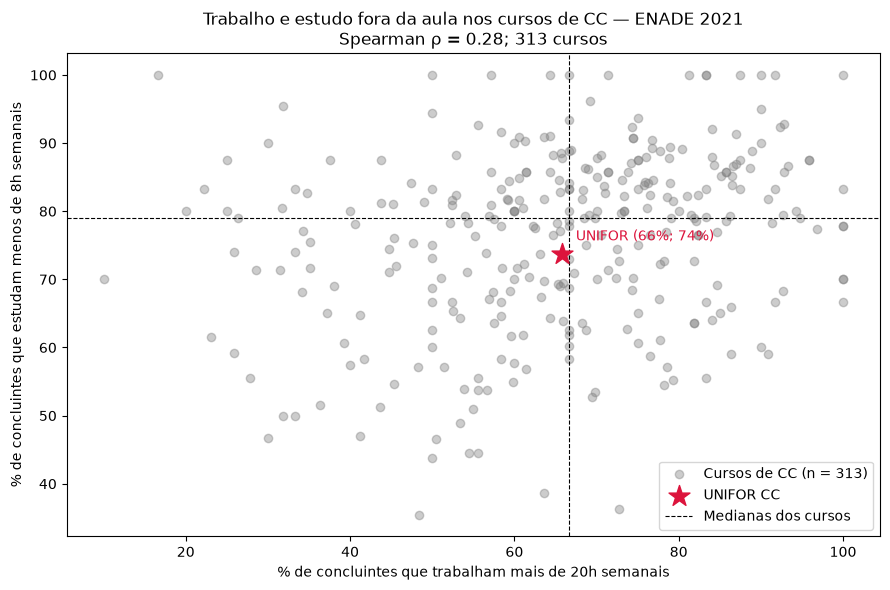

In [8]:
# Mostra a relação entre os dois percentuais por curso, com a UNIFOR destacada e as medianas de referência.
mediana_x = tabela_posicao.loc["% trabalha mais de 20h", "Mediana dos cursos de CC (%)"]
mediana_y = tabela_posicao.loc["% estuda menos de 8h", "Mediana dos cursos de CC (%)"]
unifor_x = tabela_posicao.loc["% trabalha mais de 20h", "UNIFOR (%)"]
unifor_y = tabela_posicao.loc["% estuda menos de 8h", "UNIFOR (%)"]

fig, eixo = plt.subplots(figsize=(9, 6))
eixo.scatter(
    tabela_cursos["pct_trab_20h"],
    tabela_cursos["pct_estuda_menos_8h"],
    color="gray",
    alpha=0.4,
    label=f"Cursos de CC (n = {n_cursos})",
)
eixo.scatter(
    unifor_x, unifor_y, color="crimson", marker="*", s=250, zorder=3, label="UNIFOR CC"
)
eixo.annotate(
    f"UNIFOR ({unifor_x:.0f}%; {unifor_y:.0f}%)",
    (unifor_x, unifor_y),
    xytext=(10, 10),
    textcoords="offset points",
    color="crimson",
)
eixo.axvline(
    mediana_x, color="black", linestyle="--", linewidth=0.8, label="Medianas dos cursos"
)
eixo.axhline(mediana_y, color="black", linestyle="--", linewidth=0.8)
eixo.set_xlabel("% de concluintes que trabalham mais de 20h semanais")
eixo.set_ylabel("% de concluintes que estudam menos de 8h semanais")
eixo.set_title(
    f"Trabalho e estudo fora da aula nos cursos de CC — ENADE 2021\n"
    f"Spearman ρ = {rho_principal:.2f}; {n_cursos} cursos"
)
eixo.legend(loc="lower right")
plt.tight_layout()
plt.show()

## Conclusão

- **Hipótese: CONFIRMADA, com associação fraca.** Entre os 313 cursos de CC com n ≥ 5, quanto maior o percentual que trabalha mais de 20h, maior o percentual que estuda menos de 8h (Spearman ρ = 0,28; p < 0,001, nenhuma de 10.000 permutações chegou a esse valor; Pearson r = 0,26). A direção se mantém com a definição alternativa de trabalho (C, D, E: ρ = 0,26).
- **UNIFOR:** 65,8% dos concluintes trabalham mais de 20h, perto da mediana dos cursos (66,7%; percentil 46,6), e 73,7% estudam menos de 8h, abaixo da mediana (78,9%; percentil 37,4), com 38 respondentes em cada item. Ou seja, para um nível típico de trabalho, a UNIFOR tem uma proporção menor de quem estuda pouco.
- **Falácia ecológica:** a correlação é entre cursos e não permite concluir nada sobre alunos individuais. Como QE_I10 e QE_I23 estão em arquivos separados, não se sabe se quem trabalha é quem estuda menos.
- **Limitações:** as horas de trabalho e de estudo são autodeclaradas; 16 cursos foram descartados e muitos dos restantes têm poucos respondentes; o questionário inclui concluintes ausentes na prova, porque a presença está em outro arquivo; o item de trabalho exclui estágio e bolsas; o ENADE 2021 ocorreu no contexto da pandemia; e correlação não implica causalidade.